# 수험번호를 반드시 입력하세요!

**문제를 시작하기 전에, 바로 아래 셀의 `student_id`에 본인의 수험번호를 입력하고 실행하세요.**

예: `student_id = '001234'` — 앞자리 0도 포함하여 따옴표 안에 입력하세요.


In [1]:
# 본인의 수험번호를 따옴표 안에 입력하세요. 예: '001234'
student_id = '000000'   # [정답안] 예시 번호
if not student_id or not student_id.isascii() or not student_id.isdigit():  # 비어 있거나, 영숫자 외 문자가 있거나, 숫자가 아니면 오류
    raise ValueError('수험번호를 숫자로만 입력하세요. 앞자리 0도 그대로 적습니다.')  # 수험번호 형식 오류를 알리고 실행을 멈춤
print('수험번호:', student_id)  # 입력한 수험번호를 화면에 출력

수험번호: 000000


## 코드 작성 안내
- 답안 작성과 관련 있는 셀은 앞쪽에 `답안 작성 셀`로 시작하는 마크다운 셀이 있습니다.
- 수정이 불가한 셀에는 `# 수정 금지`로 표시가 되어있습니다. 해당 주석이 있는 셀의 코드는 절대 수정하지 마세요.
- 수정 가능한 셀은 `# 수정 가능`으로 표시가 되어있습니다. 다만 셀 안에서 함수명 등 변경하면 안되는 부분도 있으니, 그런 경우 해당 셀 혹은 문항의 안내를 참고하세요.

# 문제 2-2. 이미지 분류 모델 개선 (Kaggle)

Fashion Products 이미지로 TinyViT를 학습하고, 테스트 이미지의 클래스를 예측하세요.\
Kaggle을 활용해 채점하며, 아래 셀들을 수정하여 가장 높은 accuracy를 달성하면 됩니다\.
학습 데이터는 20개 클래스에 각각 600개씩, 총 12,000개로 고정되어 있습니다.\
**# 수정 가능** 표시가 있는 증강, 모델 구조, 그리고 하이퍼파라미터 셀을 수정하세요. (꼭 모든 셀을 수정할 필요는 없습니다.)\
제공된 데이터, 클래스 번호, 이미지 크기(높이 80 × 너비 60)는 유지하세요.\
노트북과 같은 폴더의 `test.csv`에는 `id,answer` 두 열이 있으며, 처음에는 `answer`가 비어 있습니다.\
추론 셀이 `answer`를 예측값으로 채웁니다. 완료된 `test.csv`를 이름 변경 없이 Kaggle에 제출하세요.


> ## [예시 정답안]
> 증강 + AdamW/warmup-cosine + label smoothing + Dropout + eval 좌우반전 TTA. 수정 가능 셀만 바꿨습니다.

참고 자료는 [오프라인 문서 목록](docs/index.html)에서 볼 수 있습니다. `docs` 폴더를 함께 보관하세요.


## 환경 설정

아래 셀은 가상환경이 설정되어 있으며 커널이 해당 가상환경으로 잡혀 있는지를 체크합니다.
꼭 실행해서 확인 후에 진행하세요. 오류가 발생하면 이 폴더의 README.md를 참고해 환경을 다시 확인하세요.
특히 VS Code, PyCharm 환경에서 Jupyter Notebook 커널을 꼭 확인하세요.


In [2]:
# [정답안] 환경 확인 - CPU/GPU 겸용 (원본은 GPU가 없으면 여기서 멈춥니다)
import sys  # 파이썬 인터프리터 정보(sys.prefix, sys.executable)를 쓰기 위한 모듈
from pathlib import Path  # 경로를 객체로 다루는 Path 클래스

print('Python:', sys.version.split()[0])  # 현재 파이썬 버전 출력 (예: 3.12.10)
print('현재 커널:', sys.executable)  # 지금 노트북을 실행 중인 python.exe 경로 출력 → .venv인지 확인
print('작업 폴더:', Path.cwd())  # 현재 작업 폴더 출력 (상대 경로 data/... 의 기준)

expected_env = Path.cwd() / '.venv'  # 작업 폴더 아래 .venv 폴더 경로를 기대값으로 만듦
if Path(sys.prefix).resolve() != expected_env.resolve():  # 실행 중인 파이썬의 환경 폴더가 기대한 .venv와 다르면
    raise RuntimeError(  # 잘못된 커널이라는 오류를 발생
        f"{expected_env / 'Scripts' / 'python.exe'}를 노트북 커널로 선택하세요. "  # 선택해야 할 python.exe 경로를 안내 문구에 넣음
        '환경이 없다면 setup.cmd를 실행하고, 작업 폴더도 노트북이 있는 폴더로 맞추세요.'  # 안내 문구 두 번째 줄 (setup.cmd 실행 안내)
    )

import torch  # PyTorch: 텐서 연산·자동 미분·신경망
import torchvision  # torchvision: 이미지 변환(transforms)
import timm  # timm: 사전학습 이미지 모델 라이브러리 (P1_1에서 모델 생성에 사용)
print('PyTorch:', torch.__version__, '/ torchvision:', torchvision.__version__, '/ timm:', timm.__version__)  # 설치된 세 라이브러리 버전 출력

if torch.cuda.is_available():  # CUDA GPU를 쓸 수 있으면
    DEVICE, QUICK = 'cuda', False  # 장치는 GPU, QUICK(축소 실행) 모드는 끔
    print('GPU:', torch.cuda.get_device_name(0), '-> 원본 설정 그대로 실행합니다.')  # GPU 이름 출력
else:  # 그렇지 않으면 (아래 실행)
    DEVICE, QUICK = 'cpu', True  # 장치는 CPU, QUICK 모드 켬 → 뒤의 [정답안 전용] 셀이 데이터·epoch를 줄임
    print('GPU 없음 -> QUICK 모드: 학습 데이터와 epoch를 줄여 CPU에서 끝까지 실행합니다.')  # CPU 실행 안내
    print('           점수는 시험 기준보다 낮게 나옵니다. 코드 흐름 확인용입니다.')  # 점수가 낮게 나오는 이유 안내

Python: 3.12.10
현재 커널: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Scripts\python.exe
작업 폴더: C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution


C:\Users\SSAFY\Desktop\AI_Lv3_sample_solution\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PyTorch: 2.11.0+cu128 / torchvision: 0.26.0+cu128 / timm: 1.0.31
GPU: NVIDIA GeForce RTX 5060 Ti -> 원본 설정 그대로 실행합니다.


In [3]:
# 수정 금지

import csv  # CSV 읽기·쓰기
import json  # JSON 파일(classes.json) 읽기용
import time  # 학습 시간 측정용

import numpy as np  # NumPy: 이미지 배열(N, H, W, 3) 처리
from PIL import Image  # 이미지 파일 열기 (Pillow)
import matplotlib.pyplot as plt  # 그래프 그리기
import torch  # PyTorch: 텐서 연산·자동 미분·신경망
from torch import nn  # nn: 신경망 층(Linear, Conv2d 등)과 Loss 클래스
from torch.nn import functional as F  # F: 함수형 API (interpolate, log_softmax, pad 등)
from torch.utils.data import Dataset, DataLoader  # Dataset(데이터 한 개 꺼내기 규칙), DataLoader(배치로 묶기)
from torchvision import transforms as T  # 이미지 변환 모음을 T라는 이름으로 사용 (V1 API)
from sklearn.metrics import accuracy_score  # 정확도 계산 함수

torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
device = DEVICE   # [정답안] 원본은 'cuda' 고정. CPU에서도 돌도록 환경 셀의 값을 씁니다.

## 데이터 불러오기

`prepared.npz`의 학습 이미지 중 미리 정한 표본을 읽습니다. 클래스당 600개이며, 이미지가 적은 클래스는 같은 이미지가 반복됩니다.\
`classes.json`의 순서가 클래스 번호(0~19)입니다. 검증 데이터는 2,500개입니다.\
노트북과 같은 폴더의 `test.csv`에서 테스트 ID를 읽습니다. `id`에는 `.png` 확장자가 포함됩니다.\
이미지는 `data/fashion_finetune/test/<id>`에 있습니다. 빈 `answer` 열은 추론 후 채워집니다.

참고: [NumPy 파일 읽기](docs/pages/numpy.org/doc_stable_reference_generated_numpy.load--0069c633fb21.html),
[PyTorch Dataset과 DataLoader](docs/pages/docs.pytorch.org/tutorials_beginner_basics_data_tutorial--a863b5790185.html)


In [4]:
# 수정 금지

data_dir = Path('data/fashion_finetune')  # P2_2 데이터 폴더
data_path = data_dir / 'prepared.npz'  # npz 경로


In [5]:
# 수정 금지

with (data_dir / 'classes.json').open(encoding='utf-8') as file:  # classes.json 열기
    class_names = json.load(file)  # 클래스 이름 목록 읽기 (목록 순서 = 클래스 번호)
num_classes = len(class_names)  # 클래스 개수

train_indices = np.load(data_dir / 'p2_2_train_indices.npy')  # 미리 정한 학습 표본 번호 (클래스당 600, 반복 포함)
with np.load(data_path, allow_pickle=False) as data:  # npz 열기 (allow_pickle=False: 안전하게 배열만 읽음)
    train_images = data['train_images'][train_indices]  # 그 번호의 이미지만 읽음
    train_labels = data['train_labels'].reshape(-1)[train_indices]  # 같은 번호의 라벨
    val_images = data['val_images']  # 검증 이미지 배열
    val_labels = data['val_labels'].reshape(-1)  # (N,)으로 펼침

print('학습:', len(train_images), '검증:', len(val_images))  # 개수 출력
print('클래스:', num_classes, '/ 이미지 크기:', train_images[0].shape)  # 클래스 수와 이미지 크기 출력


학습: 12000 검증: 2500
클래스: 20 / 이미지 크기: (80, 60, 3)


> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [6]:
# [정답안 전용] CPU QUICK 모드에서만 학습 데이터를 클래스 비율대로 줄입니다.
if QUICK:  # CPU(QUICK) 모드일 때만
    _rng = np.random.default_rng(0)  # QUICK용 난수 생성기
    _keep = np.sort(_rng.choice(len(train_labels), size=min(3000, len(train_labels)), replace=False))  # 학습 데이터에서 3,000개 번호를 중복 없이 뽑아 정렬
    train_images, train_labels = train_images[_keep], train_labels[_keep]  # 뽑은 것만 남김
    val_images, val_labels = val_images[:1000], val_labels[:1000]  # 검증은 앞 1,000개만
    print('QUICK 모드 학습 데이터:', len(train_labels))  # 줄인 개수 출력

# **답안 작성 셀 - 학습용 증강**

`train_transform`에 증강을 추가하세요. 이미지를 읽을 때마다 변환이 적용됩니다.
검증·테스트용 `eval_transform`은 유지하세요.

참고: [RandomHorizontalFlip](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.RandomHorizontalFlip--b82b1b19a0d6.html),
[ColorJitter](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.ColorJitter--3d1cbb994bdb.html),
[Normalize](docs/pages/docs.pytorch.org/vision_stable_generated_torchvision.transforms.Normalize--38363001ace9.html)


In [7]:
# 수정 금지

mean = (0.485, 0.456, 0.406)  # ImageNet 채널별 평균 (사전학습 때 쓴 값)
std = (0.229, 0.224, 0.225)  # ImageNet 채널별 표준편차
eval_transform = T.Compose([  # 평가용 변환: 증강 없이 텐서 변환 + 정규화만
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
])


In [8]:
# 수정 가능

# [정답안] 상품 사진용 증강 (흰 배경, 가운데 정렬, 80x60 유지)
train_transform = T.Compose([  # 학습용 변환을 차례로 묶음
    T.ToPILImage(),  # numpy 배열 → PIL 이미지 (Random* 변환은 PIL/텐서만 받음)
    T.RandomHorizontalFlip(p=0.5),  # 50% 확률로 좌우 반전 (상품 종류는 그대로)
    T.RandomAffine(degrees=10, translate=(0.08, 0.08), scale=(0.9, 1.1), fill=255),  # 회전 ±10°, 이동 ±8%, 크기 0.9~1.1배, 흰 배경 채움
    T.ColorJitter(brightness=0.2, contrast=0.2, saturation=0.15),  # 밝기·대비 ±20%, 채도 ±15%
    T.ToTensor(),  # numpy(H,W,C) 0~255 → 텐서(C,H,W) 0~1 실수
    T.Normalize(mean, std),  # (값 - mean) / std 로 정규화
    T.RandomErasing(p=0.2, scale=(0.02, 0.1), value=0),  # 20% 확률로 작은 영역을 0으로 지움 (정규화 뒤라 평균색)
])

In [9]:
# 수정 가능

class FashionDataset(Dataset):  # 이미지·라벨·증강 여부로 샘플을 꺼내는 Dataset
    def __init__(self, images, labels, transform):  # 이미지·라벨·변환을 받는 생성자
        self.images = images  # 이미지 배열 저장
        self.labels = labels  # 라벨 배열 저장
        self.transform = transform  # 적용할 변환 저장

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.images)  # 데이터 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        image = self.transform(self.images[index])  # 변환 적용
        return image, int(self.labels[index])  # (이미지 텐서, 정수 라벨) 반환


In [10]:
# 수정 금지

with Path('test.csv').open(encoding='utf-8', newline='') as file:  # test.csv 열기
    test_ids = [row['id'] for row in csv.DictReader(file)]  # 테스트 이미지 id 목록 (순서 유지)


class FashionTestDataset(Dataset):  # 테스트 이미지 Dataset (정답 없음)
    def __init__(self, image_dir, ids, transform):  # 이미지 폴더, id 목록, 변환
        self.image_dir = image_dir  # 폴더 저장
        self.ids = ids  # id 저장
        self.transform = transform  # 적용할 변환 저장

    def __len__(self):  # 데이터 개수를 알려주는 함수 (DataLoader가 사용)
        return len(self.ids)  # 테스트 개수

    def __getitem__(self, index):  # index번째 샘플을 꺼내는 함수
        sample_id = self.ids[index]  # index번째 id (파일 이름)
        with Image.open(self.image_dir / sample_id) as image:  # 이미지 파일 열기
            image = self.transform(image.convert('RGB'))  # RGB로 바꾼 뒤 변환 적용
        return image, sample_id  # (이미지 텐서, id) 반환 → 예측과 id를 짝지음


print('테스트 이미지:', len(test_ids))  # 테스트 개수 출력


테스트 이미지: 2500


# **답안 작성 셀 - TinyViT와 사전학습 가중치**

TinyViT 5M의 구조를 아래 셀에 제공합니다. \
필요한 경우 모델 구조를 수정해도 됩니다. 같은 폴더의
`tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors`를 읽고 전체 파라미터를 학습합니다.\
사전학습 가중치와 입력 크기는 유지하세요.

모델 구조 수정은 반드시 수행할 필요는 없습니다

P1_1, P1_2, P2_1, P2_2는 노트북과 같은 폴더의 `tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors` 파일을 함께 사용합니다. 사전학습 가중치를 다운로드할 필요가 없습니다. 

참고: [TinyViT 논문](docs/pages/arxiv.org/abs_2207.10666--75d1c6c4be04.html),
[Microsoft 공식 구현](docs/pages/github.com/microsoft_Cream_blob_main_TinyViT_models_tiny_vit.py--7c367b0b0023.html),
[사용한 사전학습 모델](docs/pages/huggingface.co/timm_tiny_vit_5m_224.dist_in22k_ft_in1k--7b8991aa746a.html)


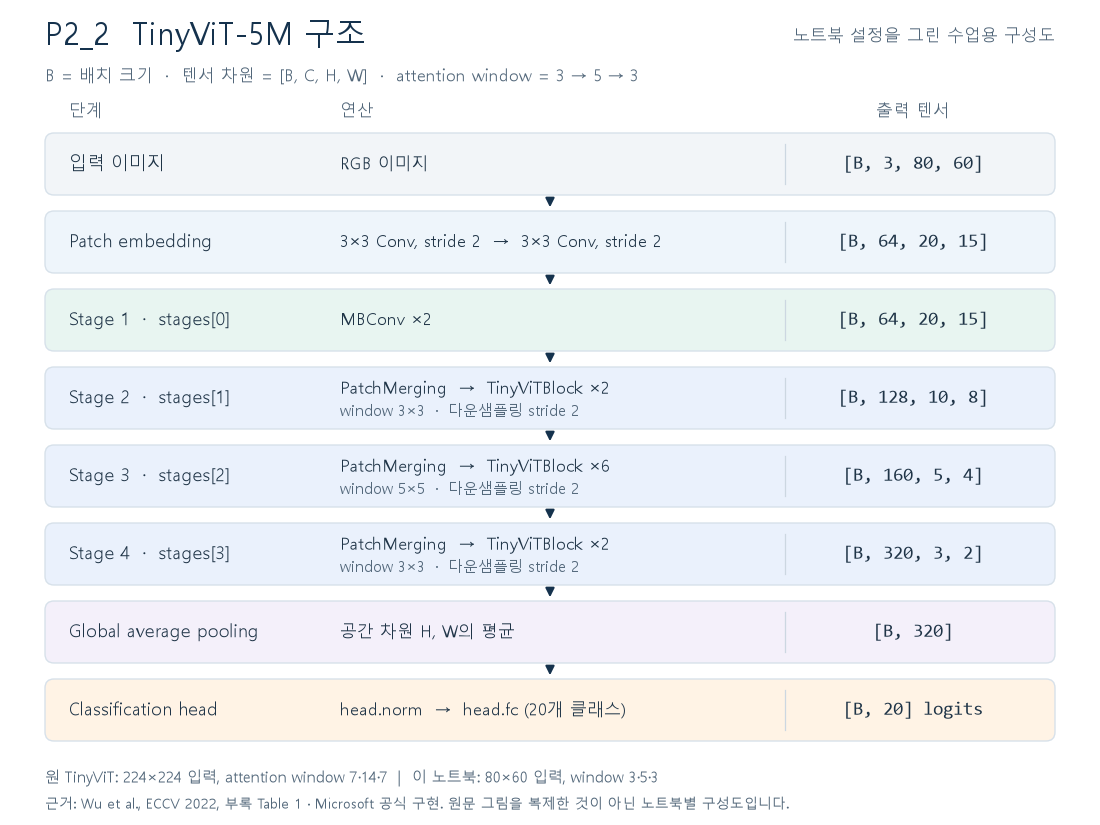

이 노트북의 구조를 그린 그림입니다. \
원 논문의 구조 설정은 [부록 Table 1](docs/pages/www.ecva.net/`papers_eccv_2022_papers_ECCV_papers_136810068-supp.pdf--b108d5257b8f.html)에서 확인할 수 있습니다.\
이 과제에서는 입력을 80×60으로, attention window 크기를 3·5·3으로 조정했습니다.


In [11]:
# 수정 가능

class ConvNorm(nn.Sequential):  # Conv2d + BatchNorm2d 묶음 (nn.Sequential을 상속)
    """Conv2d와 BatchNorm2d로 구성한 기본 블록."""  # 클래스 설명(docstring)
    def __init__(self, in_channels, out_channels, kernel_size=1,  # 입력 채널, 출력 채널, 커널 크기
                 stride=1, padding=0, groups=1, bn_weight=1.0):  # stride, padding, 그룹 수(depthwise면 채널 수), BN 초기 가중치
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv = nn.Conv2d(  # 합성곱 층
            in_channels, out_channels, kernel_size,  # 채널·커널
            stride=stride, padding=padding, groups=groups, bias=False,  # bias는 BN이 대신하므로 False
        )
        self.bn = nn.BatchNorm2d(out_channels)  # 배치 정규화 층
        nn.init.constant_(self.bn.weight, bn_weight)  # BN 스케일 초기값
        nn.init.zeros_(self.bn.bias)  # BN 이동값 0으로 초기화


class PatchEmbed(nn.Module):  # 입력 이미지를 특징 맵으로 바꾸는 첫 블록
    """원본 입력을 특징 맵으로 변환: [B, 3, 80, 60] → [B, 64, 20, 15]."""  # 클래스 설명(docstring)
    def __init__(self, dim=64):  # dim=64: 출력 채널 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(3, dim // 2, 3, stride=2, padding=1)  # 3→32채널, stride 2 (해상도 1/2)
        self.act = nn.GELU()  # GELU 활성화
        self.conv2 = ConvNorm(dim // 2, dim, 3, stride=2, padding=1)  # 32→64채널, stride 2 (해상도 1/4)

    def forward(self, x):  # 순전파 정의
        x = self.conv1(x)  # 첫 합성곱
        x = self.act(x)  # 활성화
        return self.conv2(x)  # 두 번째 합성곱 결과 반환

In [12]:
# 수정 가능

class MBConv(nn.Module):  # MobileNet식 역병목 합성곱 블록 (stage 0)
    """Stage 0: 채널 확장 → depthwise convolution → 채널 축소."""  # 클래스 설명(docstring)
    def __init__(self, dim, expand_ratio=4):  # expand_ratio=4: 중간 채널을 4배로 늘림
        super().__init__()  # nn.Module 초기화 (필수)
        hidden_dim = dim * expand_ratio  # 중간 채널 수
        self.conv1 = ConvNorm(dim, hidden_dim)  # 1×1 합성곱으로 채널 확장
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(hidden_dim, hidden_dim, 3,  # 3×3 depthwise 합성곱 (채널별로 따로)
                              padding=1, groups=hidden_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(hidden_dim, dim, bn_weight=0.0)  # 1×1로 채널 축소 (BN 가중치 0 → 처음엔 항등 연결처럼 동작)
        self.act3 = nn.GELU()  # 활성화

    def forward(self, x):  # 순전파 정의
        shortcut = x  # 잔차 연결용 입력 저장
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        x = self.conv3(x)  # 축소
        return self.act3(x + shortcut)  # 입력을 더한 뒤(잔차) 활성화


class ConvStage(nn.Module):  # MBConv 여러 개를 쌓은 stage
    def __init__(self, dim, depth):  # 채널, 블록 개수
        super().__init__()  # nn.Module 초기화 (필수)
        self.blocks = nn.Sequential(*[MBConv(dim) for _ in range(depth)])  # depth개의 MBConv를 순서대로 연결

    def forward(self, x):  # 순전파 정의
        return self.blocks(x)  # 블록들 통과


class PatchMerging(nn.Module):  # 해상도를 절반으로 줄이며 채널을 바꾸는 블록
    """해상도를 절반으로 줄이고 다음 stage의 채널 수로 변환."""  # 클래스 설명(docstring)
    def __init__(self, in_dim, out_dim):  # 입력·출력 채널
        super().__init__()  # nn.Module 초기화 (필수)
        self.conv1 = ConvNorm(in_dim, out_dim)  # 1×1로 채널 변경
        self.act1 = nn.GELU()  # 활성화
        self.conv2 = ConvNorm(out_dim, out_dim, 3, stride=2,  # 3×3 depthwise, stride 2 (해상도 1/2)
                              padding=1, groups=out_dim)  # padding 1, groups=채널 수
        self.act2 = nn.GELU()  # 활성화
        self.conv3 = ConvNorm(out_dim, out_dim)  # 1×1 합성곱

    def forward(self, x):  # 순전파 정의
        x = self.act1(self.conv1(x))  # 확장 + 활성화
        x = self.act2(self.conv2(x))  # depthwise + 활성화
        return self.conv3(x)  # 마지막 합성곱 결과 반환

In [13]:
# 수정 가능

class NormMLP(nn.Module):  # LayerNorm → Linear → GELU → Linear 다층 퍼셉트론
    def __init__(self, dim, mlp_ratio=4):  # mlp_ratio=4: 중간 차원 4배
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.fc1 = nn.Linear(dim, dim * mlp_ratio)  # 차원 확장
        self.act = nn.GELU()  # GELU 활성화
        self.fc2 = nn.Linear(dim * mlp_ratio, dim)  # 차원 복원

    def forward(self, x):  # 순전파 정의
        x = self.norm(x)  # 정규화
        x = self.fc1(x)  # 확장
        x = self.act(x)  # 활성화
        return self.fc2(x)  # 복원 결과 반환


class WindowAttention(nn.Module):  # window 안에서만 하는 multi-head self-attention
    """작은 window 안에서 수행하는 multi-head self-attention."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.num_heads = num_heads  # head 수 저장
        self.head_dim = dim // num_heads  # head 하나의 차원
        self.scale = self.head_dim ** -0.5  # 점수 스케일 1/√(head 차원)
        self.norm = nn.LayerNorm(dim)  # 토큰별 LayerNorm
        self.qkv = nn.Linear(dim, dim * 3)  # Q, K, V를 한 번에 만드는 Linear (출력 3배)
        self.proj = nn.Linear(dim, dim)  # head를 합친 뒤 출력 투영

        # window 내 두 위치 사이의 상대 거리에 따른 학습 가능한 bias
        coords = torch.stack(torch.meshgrid(  # window 안 모든 위치의 (행, 열) 좌표
            torch.arange(window_size), torch.arange(window_size), indexing="ij"  # 0..window-1 격자
        )).flatten(1)  # (2, window²) 모양으로 펼침
        offsets = (coords[:, :, None] - coords[:, None, :]).abs()  # 모든 위치 쌍의 행·열 거리 (절댓값)
        bias_indices = offsets[0] * window_size + offsets[1]  # 거리 (dy, dx)를 bias 표의 번호로 바꿈
        self.register_buffer("attention_bias_idxs", bias_indices, persistent=False)  # 번호표를 버퍼로 저장 (학습 안 함, state_dict에도 안 넣음)
        self.attention_biases = nn.Parameter(  # 거리별 학습 가능한 bias 표
            torch.zeros(num_heads, window_size * window_size)  # (head 수, window²) 크기, 0으로 시작
        )

    def forward(self, x):  # 순전파 정의
        batch_size, num_tokens, dim = x.shape  # (window 개수×배치, 토큰 수, 차원)
        x = self.norm(x)  # 정규화

        # 체크포인트의 QKV 배치 순서: 각 head 안에 Q, K, V가 들어 있습니다.
        qkv = self.qkv(x).reshape(  # QKV 계산 후 모양 변경
            batch_size, num_tokens, self.num_heads, 3 * self.head_dim  # (B, N, head, 3×head 차원): head마다 [q|k|v]가 붙어 있음
        )
        qkv = qkv.transpose(1, 2)  # (B, head, N, 3×head 차원)
        q, k, v = qkv.chunk(3, dim=-1)  # 마지막 축을 3등분 → q, k, v

        attention = (q * self.scale) @ k.transpose(-2, -1)  # 스케일된 Q·Kᵀ = 위치 쌍별 유사도 (B, head, N, N)
        bias = self.attention_biases[:, self.attention_bias_idxs]  # 각 위치 쌍의 거리에 해당하는 bias를 꺼냄
        attention = (attention + bias.unsqueeze(0)).softmax(dim=-1)  # bias를 더하고 softmax → 주의 가중치
        x = attention @ v  # 가중치로 V를 섞음
        x = x.transpose(1, 2).reshape(batch_size, num_tokens, dim)  # head들을 다시 이어붙여 (B, N, 차원)
        return self.proj(x)  # 출력 투영 결과 반환

In [14]:
# 수정 가능

class TinyViTBlock(nn.Module):  # attention + local conv + MLP 블록
    """윈도 어텐션 → 지역 합성곱 → 다층 퍼셉트론."""  # 클래스 설명(docstring)
    def __init__(self, dim, num_heads, window_size):  # 차원, head 수, window 한 변 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.window_size = window_size  # window 크기 저장
        self.attn = WindowAttention(dim, num_heads, window_size)  # window attention 층
        self.local_conv = ConvNorm(dim, dim, 3, padding=1, groups=dim)  # 3×3 depthwise 합성곱 (가까운 위치 정보 섞기)
        self.mlp = NormMLP(dim)  # MLP 층

    def forward(self, x):  # 순전파 정의
        # 이 블록 안에서는 [B, H, W, C] 순서로 처리합니다.
        batch_size, height, width, channels = x.shape  # (B, H, W, C) 모양 분해
        shortcut = x  # 잔차 연결용 입력 저장
        window = self.window_size  # window 크기

        # 해상도가 window 크기의 배수가 아닐 때 오른쪽·아래쪽에 padding
        pad_h = (window - height % window) % window  # 높이를 window 배수로 맞출 아래쪽 padding
        pad_w = (window - width % window) % window  # 너비를 window 배수로 맞출 오른쪽 padding
        x = F.pad(x, (0, 0, 0, pad_w, 0, pad_h))  # (채널, 너비, 높이) 순서로 0 padding
        padded_h, padded_w = height + pad_h, width + pad_w  # padding 후 크기
        num_h, num_w = padded_h // window, padded_w // window  # 세로·가로 window 개수

        # 이미지 → 여러 window
        x = x.reshape(batch_size, num_h, window, num_w, window, channels)  # window 단위로 나눔
        x = x.transpose(2, 3).reshape(-1, window * window, channels)  # (B×window 개수, window², C) 토큰 묶음으로
        x = self.attn(x)  # window마다 attention

        # 여러 window → 이미지
        x = x.reshape(batch_size, num_h, num_w, window, window, channels)  # 다시 window 격자 모양으로
        x = x.transpose(2, 3).reshape(batch_size, padded_h, padded_w, channels)  # 이미지 모양 (B, H', W', C)로 복원
        x = x[:, :height, :width, :].contiguous()  # padding 부분 잘라냄
        x = shortcut + x  # 잔차 연결

        x = x.permute(0, 3, 1, 2)  # (B, C, H, W)로 바꿈 (합성곱 입력 형식)
        x = self.local_conv(x)  # local 합성곱
        x = x.flatten(2).transpose(1, 2)  # (B, H×W, C) 토큰 형식으로
        x = x + self.mlp(x)  # MLP + 잔차 연결
        return x.reshape(batch_size, height, width, channels)  # (B, H, W, C)로 되돌려 반환


class TinyViTStage(nn.Module):  # PatchMerging + TinyViTBlock 여러 개
    def __init__(self, in_dim, out_dim, depth, num_heads, window_size):  # 입력·출력 채널, 블록 수, head 수, window 크기
        super().__init__()  # nn.Module 초기화 (필수)
        self.downsample = PatchMerging(in_dim, out_dim)  # 해상도 절반 + 채널 변경
        self.blocks = nn.Sequential(*[  # 블록들을 순서대로 연결
            TinyViTBlock(out_dim, num_heads, window_size) for _ in range(depth)  # depth개의 attention 블록
        ])

    def forward(self, x):  # 순전파 정의
        x = self.downsample(x)  # 해상도 줄이기 (B, C, H, W)
        x = x.permute(0, 2, 3, 1)  # (B, H, W, C)로 바꿈 (블록 입력 형식)
        x = self.blocks(x)  # 블록들 통과
        return x.permute(0, 3, 1, 2)  # (B, C, H, W)로 되돌려 반환


In [15]:
# 수정 가능

from safetensors.torch import load_file  # safetensors 형식 가중치 파일을 읽는 함수

class ClassifierHead(nn.Module):  # 평균 풀링 → LayerNorm → Linear 분류 head
    def __init__(self, dim, num_classes):  # 입력 차원, 클래스 수
        super().__init__()  # nn.Module 초기화 (필수)
        self.norm = nn.LayerNorm(dim, eps=1e-5)  # 정규화 층
        self.fc = nn.Linear(dim, num_classes)  # 분류층

    def forward(self, x):  # 순전파 정의
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.norm(x)  # 정규화
        return self.fc(x)  # 클래스 점수 반환


def load_pretrained_weights(model):  # 로컬 사전학습 가중치를 모델에 넣는 함수
    """제공된 로컬 가중치를 읽고 상대 위치 bias만 입력 크기에 맞게 보간합니다."""  # 함수 설명(docstring)
    path = Path('tiny_vit_5m_224.dist_in22k_ft_in1k.safetensors')  # 노트북 옆에 있어야 할 가중치 파일
    if not path.is_file():  # 파일이 없으면
        raise FileNotFoundError(  # 오류 발생
            f'사전학습 가중치 파일을 찾을 수 없습니다: {path.resolve()}\n'  # 찾은 절대 경로를 오류 문구에 넣음
            '제공된 가중치 파일을 노트북과 같은 폴더에 두고, 작업 폴더를 해당 폴더로 맞추세요.'  # 오류 안내 두 번째 줄
        )
    weights = load_file(str(path))  # 가중치를 {이름: 텐서} 사전으로 읽음
    target = model.state_dict()  # 현재 모델의 {이름: 텐서} (모양 비교용)
    for name, value in weights.items():  # 가중치를 하나씩 돌며
        if name.endswith('attention_biases') and value.shape != target[name].shape:  # attention 상대 위치 bias인데 모양이 다르면 (window 크기를 줄였기 때문)
            num_heads, length = value.shape  # (head 수, window²) 모양 분해
            old_window = int(length ** 0.5)  # 원래 window 한 변 길이 (예: 49 → 7)
            new_window = int(target[name].shape[1] ** 0.5)  # 새 window 한 변 길이 (예: 9 → 3)
            weights[name] = F.interpolate(  # bias를 2차원 격자로 보고 크기를 줄임
                value.float().reshape(1, num_heads, old_window, old_window),  # (1, head, 원래 window, 원래 window) 이미지처럼 바꿈
                size=(new_window, new_window),  # 목표 크기
                mode='bicubic', antialias=True,  # bicubic 보간 + antialias (부드럽게 축소)
            ).reshape(num_heads, new_window * new_window)  # 다시 (head, 새 window²) 모양으로
    model.load_state_dict(weights, strict=True)  # strict=True: 모든 이름·모양이 정확히 맞아야 로딩 (빠진 것 있으면 오류)


In [16]:
# 수정 가능

class FashionModel(nn.Module):  # 20종 분류용 TinyViT 5M
    """원본 크기의 이미지에서 전체 파라미터를 미세조정하는 TinyViT 5M입니다.

    [정답안] 구조 변경
      1) head 앞 Dropout(0.2): 12,000장으로 5M 모델 전체를 학습하므로 과적합 완화
      2) 평가 모드에서 좌우 반전 TTA: 추론 셀은 수정 금지지만 model(images)를 부르므로,
         eval일 때 원본과 좌우 반전 logits를 평균해 돌려줍니다. 가중치 수는 그대로.
    """
    def __init__(self, drop=0.2, tta=True):  # Dropout 비율, TTA 사용 여부
        super().__init__()  # nn.Module 초기화 (필수)
        self.patch_embed = PatchEmbed(dim=64)  # 입력 → 64채널 특징 맵
        self.stages = nn.Sequential(  # 4개 stage 묶음
            ConvStage(dim=64, depth=2),  # stage 0: MBConv 2개 (64채널)
            TinyViTStage(64, 128, depth=2, num_heads=4, window_size=3),  # stage 1: 128채널, 블록 2, head 4, window 3
            TinyViTStage(128, 160, depth=6, num_heads=5, window_size=5),  # stage 2: 160채널, 블록 6, head 5, window 5
            TinyViTStage(160, 320, depth=2, num_heads=10, window_size=3),  # stage 3: 320채널, 블록 2, head 10, window 3
        )
        self.head = ClassifierHead(320, num_classes=1000)  # 원래 1000종 head (가중치 로딩을 위해 같은 모양으로 만듦)
        load_pretrained_weights(self)  # 사전학습 가중치 로딩 (strict)
        self.head.fc = nn.Linear(320, num_classes)  # 분류층을 20종 출력으로 교체
        self.dropout = nn.Dropout(drop)  # 분류층 앞 Dropout
        self.tta = tta  # TTA 여부 저장

    def forward_once(self, x):  # 입력 한 번에 대한 순전파
        x = self.patch_embed(x)  # 특징 맵 만들기
        x = self.stages[0](x)  # stage 0
        x = self.stages[1](x)  # stage 1
        x = self.stages[2](x)  # stage 2
        x = self.stages[3](x)  # stage 3
        x = x.mean(dim=(2, 3))  # 공간(H, W) 평균 → (B, C) 특징 벡터
        x = self.head.norm(x)  # LayerNorm
        return self.head.fc(self.dropout(x))  # Dropout 후 분류

    def forward(self, x):  # 순전파 정의
        logits = self.forward_once(x)  # 원본 입력 결과
        if self.tta and not self.training:  # 평가 모드이고 TTA를 켰으면
            logits = (logits + self.forward_once(torch.flip(x, dims=[3]))) / 2  # 좌우 반전(너비 축 3) 결과와 평균
        return logits  # logits 반환

# **답안 작성 셀 - 학습 설정**

아래 설정을 바꾼 뒤 DataLoader와 학습 셀을 다시 실행하세요.\
학습할 때마다 같은 사전학습 가중치에서 시작하며, 매 epoch의 검증 Accuracy을 비교합니다.

참고: [Adam](docs/pages/docs.pytorch.org/docs_stable_generated_torch.optim.Adam--6d92a2e47a7f.html)


In [17]:
# 수정 가능

# [정답안] 전체 미세조정 설정
batch_size = 64  # batch 크기: 한 번에 학습할 이미지 수
learning_rate = 0.0005       # AdamW 최대 학습률 (warmup 후 cosine으로 감소)
epochs = 30  # 30 epoch
weight_decay = 0.05  # weight decay 0.05
warmup_epochs = 2  # warmup 2 epoch
label_smoothing = 0.1  # label smoothing 0.1

> **[정답안 전용 셀]** 시험 노트북에는 없는 셀입니다. GPU가 있으면 아무 일도 하지 않습니다.

In [18]:
if QUICK:  # CPU(QUICK) 모드일 때만
    epochs, warmup_epochs = 3, 1  # QUICK: 3 epoch, warmup 1
    print('QUICK 모드 epoch:', epochs)  # 줄인 epoch 출력

In [19]:
# 수정 금지
output_dir = Path('outputs')  # 결과 저장 폴더
output_dir.mkdir(exist_ok=True)  # 폴더가 없으면 만듦 (있으면 그대로)
checkpoint = output_dir / f'P2_2_{student_id}.pt'  # 체크포인트
history_path = output_dir / f'P2_2_{student_id}_history.csv'  # 기록 CSV
submission_path = Path('test.csv')  # 제출 파일 = 노트북 옆 test.csv


In [20]:
# 수정 금지

train_dataset = FashionDataset(train_images, train_labels, train_transform)  # 학습 Dataset (증강)
val_dataset = FashionDataset(val_images, val_labels, eval_transform)  # 검증 Dataset
test_dataset = FashionTestDataset(data_dir / 'test', test_ids, eval_transform)  # 테스트 Dataset (평가 변환)
train_loader = DataLoader(train_dataset, batch_size=batch_size, shuffle=True, num_workers=0)  # 학습 DataLoader (num_workers=0: 메인 프로세스에서 읽기, Windows 안전)
val_loader = DataLoader(val_dataset, batch_size=batch_size, shuffle=False, num_workers=0)  # 검증 DataLoader
test_loader = DataLoader(test_dataset, batch_size=batch_size, shuffle=False, num_workers=0)  # 테스트 DataLoader (순서 유지)


# **답안 작성 셀 - 학습과 검증**

Cross Entropy로 학습하며 매 epoch의 학습·검증 Loss와 검증 Accuracy을 출력합니다.\
검증 Accuracy이 가장 높을 때의 가중치를 `outputs/P2_2_<수험번호>.pt`에 저장합니다.\
학습 기록은 `outputs/P2_2_<수험번호>_history.csv`에 저장합니다.

참고: [PyTorch 학습·검증 루프](docs/pages/docs.pytorch.org/tutorials_beginner_basics_optimization_tutorial--ad1a8b720acf.html)


In [21]:
# 수정 가능

def train_one_epoch(model, loader, optimizer, loss_fn, scheduler=None):  # 스케줄러를 받을 수 있게 확장한 학습 함수
    model.train()  # 학습 모드 (Dropout·BN이 학습 동작)
    total_loss = 0  # Loss 누적값
    sample_count = 0  # 샘플 수 누적값
    for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
        images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
        labels = labels.to(device)  # 라벨도 같은 장치로
        optimizer.zero_grad()  # gradient를 0으로 초기화 (다음 배치에 누적되지 않게)
        logits = model(images)  # 순전파 → logits (B, 클래스 수)
        loss = loss_fn(logits, labels)  # Loss 계산
        loss.backward()  # 역전파: 각 파라미터의 gradient 계산
        torch.nn.utils.clip_grad_norm_(model.parameters(), 5.0)   # [정답안] 큰 gradient 방지
        optimizer.step()  # gradient로 파라미터 갱신
        if scheduler is not None:  # 스케줄러가 있으면
            scheduler.step()                                    # [정답안] 배치마다 스케줄 갱신
        total_loss += loss.item() * len(labels)  # 배치 평균 Loss × 배치 크기 = 배치 합계를 누적
        sample_count += len(labels)  # 처리한 샘플 수 누적
    return total_loss / sample_count  # 샘플 평균 Loss 반환


def evaluate(model, loader, loss_fn):  # 검증 함수
    model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
    total_loss = 0  # Loss 누적값
    predictions, targets = [], []  # 예측과 정답을 모을 리스트
    with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
        for images, labels in loader:  # DataLoader에서 배치를 하나씩 꺼냄
            images = images.to(device)  # 이미지를 GPU/CPU 장치로 이동
            labels = labels.to(device)  # 라벨도 같은 장치로
            logits = model(images)  # 순전파 → logits (B, 클래스 수)
            total_loss += loss_fn(logits, labels).item() * len(labels)  # 배치 Loss 합계 누적
            predictions.extend(logits.argmax(1).cpu().tolist())  # 가장 큰 점수의 클래스 번호를 예측으로 저장
            targets.extend(labels.cpu().tolist())  # 정답 저장
    accuracy = accuracy_score(targets, predictions)  # 정확도 계산
    return total_loss / len(targets), accuracy  # 평균 Loss와 정확도 반환

In [22]:
# 수정 가능
import math  # cos 계산용

torch.manual_seed(42)  # PyTorch 난수 시드 고정 (가중치 초기화, shuffle 순서)
model = FashionModel().to(device)  # 모델 생성 후 장치로

# [정답안] AdamW + weight decay는 가중치 행렬에만 (bias, norm, attention bias 제외)
decay, no_decay = [], []  # weight decay를 줄 파라미터 / 안 줄 파라미터
for name, param in model.named_parameters():  # 모든 파라미터를 이름과 함께 돌며
    if param.ndim <= 1 or name.endswith('attention_biases'):  # 1차원(bias, Norm 가중치)이거나 attention bias면
        no_decay.append(param)  # decay 제외 목록
    else:  # 그렇지 않으면 (아래 실행)
        decay.append(param)  # 나머지(가중치 행렬)는 decay 목록
optimizer = torch.optim.AdamW([  # AdamW: 그룹별로 다른 weight decay
    {'params': decay, 'weight_decay': weight_decay},  # 가중치 행렬 그룹
    {'params': no_decay, 'weight_decay': 0.0},  # bias·norm 그룹 (decay 0)
], lr=learning_rate)  # 공통 최대 학습률

# [정답안] warmup -> cosine 감소 (배치 단위)
total_steps = epochs * len(train_loader)  # 전체 배치 수 = epoch × 한 epoch 배치 수
warmup_steps = warmup_epochs * len(train_loader)  # warmup 배치 수
def lr_lambda(step):  # 배치 번호 → 학습률 배율을 돌려주는 함수
    if step < warmup_steps:  # warmup 구간이면
        return (step + 1) / warmup_steps  # 0에서 1까지 직선으로 증가
    progress = (step - warmup_steps) / max(1, total_steps - warmup_steps)  # warmup 이후 진행률 0~1
    return 0.5 * (1 + math.cos(math.pi * progress))  # cosine으로 1에서 0까지 부드럽게 감소
scheduler = torch.optim.lr_scheduler.LambdaLR(optimizer, lr_lambda)  # 배율 함수로 학습률을 조절하는 스케줄러

loss_fn = nn.CrossEntropyLoss(label_smoothing=label_smoothing)   # Cross Entropy (+ smoothing)
eval_loss_fn = nn.CrossEntropyLoss()  # 검증 Loss는 smoothing 없는 CE로 계산
best_accuracy = -1  # 최고 정확도
history = []  # epoch별 기록
started = time.perf_counter()  # 시작 시각

for epoch in range(epochs):  # epoch 반복
    train_loss = train_one_epoch(model, train_loader, optimizer, loss_fn, scheduler)  # 스케줄러까지 넘겨 1 epoch 학습
    val_loss, val_accuracy = evaluate(model, val_loader, eval_loss_fn)  # 검증 (정확도)
    history.append({  # 기록 추가 시작
        'epoch': epoch + 1,  # epoch 번호 (1부터)
        'train_loss': train_loss,  # 학습 Loss
        'val_loss': val_loss,  # 검증 Loss
        'val_accuracy': val_accuracy,  # 검증 정확도 기록
    })
    if val_accuracy > best_accuracy:  # 최고보다 좋으면
        best_accuracy = val_accuracy  # 갱신
        torch.save(model.state_dict(), checkpoint)  # 가중치만 파일로 저장 (best 체크포인트)
    print(f'{epoch + 1:2d}/{epochs}  학습 Loss: {train_loss:.4f}  '  # epoch 결과 출력
          f'검증 Loss: {val_loss:.4f}  검증 Accuracy: {val_accuracy:.4f}')  # 검증 Loss·정확도

with history_path.open('w', encoding='utf-8', newline='') as file:  # 기록 CSV를 매 epoch 덮어씀
    writer = csv.DictWriter(file, fieldnames=['epoch', 'train_loss', 'val_loss', 'val_accuracy'])  # CSV 열 이름
    writer.writeheader()  # 머리글 쓰기
    writer.writerows(history)  # 모든 행 쓰기
print(f'최고 검증 Accuracy: {best_accuracy:.4f} / 학습 시간: {time.perf_counter() - started:.1f}초')  # 최고 정확도와 시간 출력
print('체크포인트:', checkpoint)  # 체크포인트 경로 출력

 1/30  학습 Loss: 2.2580  검증 Loss: 0.6758  검증 Accuracy: 0.8328


 2/30  학습 Loss: 0.9834  검증 Loss: 0.3840  검증 Accuracy: 0.9064


 3/30  학습 Loss: 0.8754  검증 Loss: 0.3565  검증 Accuracy: 0.9112


 4/30  학습 Loss: 0.8317  검증 Loss: 0.3551  검증 Accuracy: 0.9132


 5/30  학습 Loss: 0.8018  검증 Loss: 0.3501  검증 Accuracy: 0.9152


 6/30  학습 Loss: 0.7817  검증 Loss: 0.3035  검증 Accuracy: 0.9272


... (20 outputs left out)

27/30  학습 Loss: 0.6347  검증 Loss: 0.2664  검증 Accuracy: 0.9444


28/30  학습 Loss: 0.6383  검증 Loss: 0.2647  검증 Accuracy: 0.9432


29/30  학습 Loss: 0.6349  검증 Loss: 0.2622  검증 Accuracy: 0.9440


30/30  학습 Loss: 0.6346  검증 Loss: 0.2632  검증 Accuracy: 0.9432
최고 검증 Accuracy: 0.9476 / 학습 시간: 696.9초
체크포인트: outputs\P2_2_000000.pt


### [정답안 해설] 성능을 올린 요소
| 요소 | 내용 | 이유 |
|---|---|---|
| 증강 | 좌우 반전, 작은 이동·회전·확대(흰 배경 채움), 약한 색 변화, 작은 지우기 | 클래스당 600장(일부 반복) → 반복 이미지 암기 방지 |
| 옵티마이저 | AdamW, weight decay 0.05 (bias·norm 제외) | ViT 계열 미세조정의 기본값 |
| 스케줄 | warmup 2 epoch → cosine | 사전학습 가중치가 초반 큰 gradient에 망가지는 것 방지, 후반 미세 수렴 |
| Loss | CE + label smoothing 0.1 | Shirts/Tshirts/Tops, 신발 3종처럼 비슷한 클래스 과신 방지 |
| 구조 | head 앞 Dropout 0.2, eval 때 좌우 반전 TTA | 과적합 완화 / 추론 셀 수정 없이 예측 안정화 |
| gradient clipping | norm 5.0 | 학습 안정 |

- 추론 셀(수정 금지)은 `model(images)`만 부르므로, TTA를 **모델의 eval forward 안에** 넣은 것이 요령입니다.
- 제출: 추론 셀이 채운 `test.csv`를 이름 그대로 Kaggle에 냅니다. 이 폴더에서는 `python _grading/score_p2_2.py`로 로컬 채점합니다.

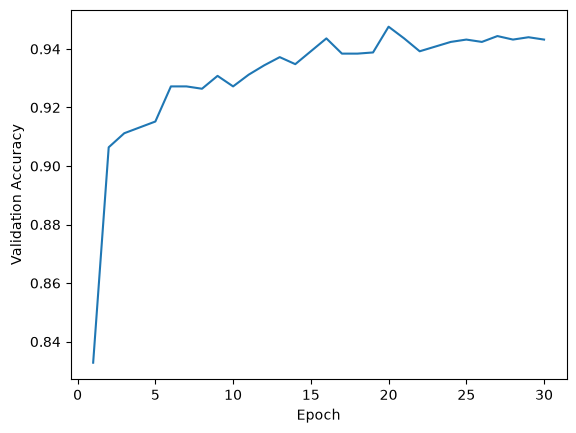

In [23]:
# 수정 가능

plt.plot([row['epoch'] for row in history], [row['val_accuracy'] for row in history])  # epoch별 검증 정확도 그래프
plt.xlabel('Epoch')  # x축 이름
plt.ylabel('Validation Accuracy')  # y축 이름
plt.show()  # 그림 표시


## 테스트 추론과 Kaggle 제출

가장 좋은 검증 가중치를 다시 불러와 테스트 DataLoader로 예측합니다.\
노트북과 같은 폴더의 `test.csv`에서 읽은 ID 순서를 유지하고, `answer` 열을 예측값으로 채워 같은 파일에 저장합니다.\
`answer`는 `classes.json` 순서의 정수 클래스 번호(0~19)입니다.\
완성된 **`test.csv`를 그대로 Kaggle에 제출**하세요. 파일명에 수험번호를 붙이지 않습니다.\
추론 셀을 다시 실행하면 `answer`가 새 예측값으로 갱신됩니다.

참고: [모델 가중치 저장과 불러오기](docs/pages/docs.pytorch.org/tutorials_beginner_basics_saveloadrun_tutorial--102f53b27159.html)


In [24]:
# 수정 금지

model.load_state_dict(torch.load(checkpoint, map_location=device, weights_only=True))  # 저장된 best 가중치를 다시 불러옴 (weights_only=True: 안전 로딩)
model.eval()  # 평가 모드 (Dropout 끔, BN은 저장된 통계 사용)
predicted_ids, predictions = [], []  # id와 예측을 모을 리스트
with torch.no_grad():  # gradient 기록 없이 계산 (메모리·속도 절약)
    for images, ids in test_loader:  # 테스트 배치 반복 (라벨 대신 id)
        logits = model(images.to(device))  # 장치로 옮겨 순전파
        predictions.extend(logits.argmax(dim=1).cpu().tolist())  # 가장 큰 점수의 클래스 번호
        predicted_ids.extend(ids)  # id 저장 (예측과 같은 순서)

with submission_path.open('w', encoding='utf-8', newline='') as file:  # test.csv를 쓰기 모드로 (덮어씀)
    writer = csv.writer(file)  # CSV 작성기
    writer.writerow(['id', 'answer'])  # 머리글
    writer.writerows(zip(predicted_ids, predictions))  # (id, 예측) 행들
print(f'제출 파일: {submission_path} / {len(predictions)}개 예측')  # 예측 개수 출력


제출 파일: test.csv / 2500개 예측


> **[정답안 전용 셀]** 로컬 채점 (Kaggle 대신). 정답 파일은 `_grading/`에 있습니다.

In [25]:
# [정답안 전용] 로컬 채점
import subprocess, sys  # 다른 프로그램 실행용, 파이썬 경로
print(subprocess.run([sys.executable, '_grading/score_p2_2.py'], capture_output=True, text=True).stdout)  # 로컬 채점 스크립트를 실행하고 결과 출력

[Local Kaggle] test accuracy: 0.9516  (2500장)



<details>
<summary>코드 라이선스 고지</summary>

수정하여 사용한 PyTorch Tutorials 코드의 사용 고지입니다. 과제의 평가 기준과는 무관합니다.

```text
BSD 3-Clause License

Copyright (c) 2017-2022, Pytorch contributors
All rights reserved.

Redistribution and use in source and binary forms, with or without
modification, are permitted provided that the following conditions are met:

* Redistributions of source code must retain the above copyright notice, this
  list of conditions and the following disclaimer.
* Redistributions in binary form must reproduce the above copyright notice,
  this list of conditions and the following disclaimer in the documentation
  and/or other materials provided with the distribution.
* Neither the name of the copyright holder nor the names of its
  contributors may be used to endorse or promote products derived from
  this software without specific prior written permission.
THIS SOFTWARE IS PROVIDED BY THE COPYRIGHT HOLDERS AND CONTRIBUTORS "AS IS"
AND ANY EXPRESS OR IMPLIED WARRANTIES, INCLUDING, BUT NOT LIMITED TO, THE
IMPLIED WARRANTIES OF MERCHANTABILITY AND FITNESS FOR A PARTICULAR PURPOSE ARE
DISCLAIMED. IN NO EVENT SHALL THE COPYRIGHT HOLDER OR CONTRIBUTORS BE LIABLE
FOR ANY DIRECT, INDIRECT, INCIDENTAL, SPECIAL, EXEMPLARY, OR CONSEQUENTIAL
DAMAGES (INCLUDING, BUT NOT LIMITED TO, PROCUREMENT OF SUBSTITUTE GOODS OR
SERVICES; LOSS OF USE, DATA, OR PROFITS; OR BUSINESS INTERRUPTION) HOWEVER
CAUSED AND ON ANY THEORY OF LIABILITY, WHETHER IN CONTRACT, STRICT LIABILITY,
OR TORT (INCLUDING NEGLIGENCE OR OTHERWISE) ARISING IN ANY WAY OUT OF THE USE
OF THIS SOFTWARE, EVEN IF ADVISED OF THE POSSIBILITY OF SUCH DAMAGE.
```



### 모델 코드 사용 고지

TinyViT 구성 블록은 Microsoft TinyViT 및 timm의 구현을 교육용으로 수정했습니다. 이 노트북에서는 TinyViT 5M, 직사각형 입력, 작은 window, 명시적인 stage별 forward와 가중치 로딩을 사용합니다.

Microsoft TinyViT: Copyright (c) Microsoft Corporation. MIT License.

timm: Copyright 2019 Ross Wightman. Apache License, Version 2.0.

```text
MIT License

Copyright (c) Microsoft Corporation.

Permission is hereby granted, free of charge, to any person obtaining a copy
of this software and associated documentation files (the "Software"), to deal
in the Software without restriction, including without limitation the rights
to use, copy, modify, merge, publish, distribute, sublicense, and/or sell
copies of the Software, and to permit persons to whom the Software is
furnished to do so, subject to the following conditions:

The above copyright notice and this permission notice shall be included in all
copies or substantial portions of the Software.

THE SOFTWARE IS PROVIDED "AS IS", WITHOUT WARRANTY OF ANY KIND, EXPRESS OR
IMPLIED, INCLUDING BUT NOT LIMITED TO THE WARRANTIES OF MERCHANTABILITY,
FITNESS FOR A PARTICULAR PURPOSE AND NONINFRINGEMENT. IN NO EVENT SHALL THE
AUTHORS OR COPYRIGHT HOLDERS BE LIABLE FOR ANY CLAIM, DAMAGES OR OTHER
LIABILITY, WHETHER IN AN ACTION OF CONTRACT, TORT OR OTHERWISE, ARISING FROM,
OUT OF OR IN CONNECTION WITH THE SOFTWARE OR THE USE OR OTHER DEALINGS IN THE
SOFTWARE.
```

```text
Apache License
                           Version 2.0, January 2004
                        http://www.apache.org/licenses/

   TERMS AND CONDITIONS FOR USE, REPRODUCTION, AND DISTRIBUTION

   1. Definitions.

      "License" shall mean the terms and conditions for use, reproduction,
      and distribution as defined by Sections 1 through 9 of this document.

      "Licensor" shall mean the copyright owner or entity authorized by
      the copyright owner that is granting the License.

      "Legal Entity" shall mean the union of the acting entity and all
      other entities that control, are controlled by, or are under common
      control with that entity. For the purposes of this definition,
      "control" means (i) the power, direct or indirect, to cause the
      direction or management of such entity, whether by contract or
      otherwise, or (ii) ownership of fifty percent (50%) or more of the
      outstanding shares, or (iii) beneficial ownership of such entity.

      "You" (or "Your") shall mean an individual or Legal Entity
      exercising permissions granted by this License.

      "Source" form shall mean the preferred form for making modifications,
      including but not limited to software source code, documentation
      source, and configuration files.

      "Object" form shall mean any form resulting from mechanical
      transformation or translation of a Source form, including but
      not limited to compiled object code, generated documentation,
      and conversions to other media types.

      "Work" shall mean the work of authorship, whether in Source or
      Object form, made available under the License, as indicated by a
      copyright notice that is included in or attached to the work
      (an example is provided in the Appendix below).

      "Derivative Works" shall mean any work, whether in Source or Object
      form, that is based on (or derived from) the Work and for which the
      editorial revisions, annotations, elaborations, or other modifications
      represent, as a whole, an original work of authorship. For the purposes
      of this License, Derivative Works shall not include works that remain
      separable from, or merely link (or bind by name) to the interfaces of,
      the Work and Derivative Works thereof.

      "Contribution" shall mean any work of authorship, including
      the original version of the Work and any modifications or additions
      to that Work or Derivative Works thereof, that is intentionally
      submitted to Licensor for inclusion in the Work by the copyright owner
      or by an individual or Legal Entity authorized to submit on behalf of
      the copyright owner. For the purposes of this definition, "submitted"
      means any form of electronic, verbal, or written communication sent
      to the Licensor or its representatives, including but not limited to
      communication on electronic mailing lists, source code control systems,
      and issue tracking systems that are managed by, or on behalf of, the
      Licensor for the purpose of discussing and improving the Work, but
      excluding communication that is conspicuously marked or otherwise
      designated in writing by the copyright owner as "Not a Contribution."

      "Contributor" shall mean Licensor and any individual or Legal Entity
      on behalf of whom a Contribution has been received by Licensor and
      subsequently incorporated within the Work.

   2. Grant of Copyright License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      copyright license to reproduce, prepare Derivative Works of,
      publicly display, publicly perform, sublicense, and distribute the
      Work and such Derivative Works in Source or Object form.

   3. Grant of Patent License. Subject to the terms and conditions of
      this License, each Contributor hereby grants to You a perpetual,
      worldwide, non-exclusive, no-charge, royalty-free, irrevocable
      (except as stated in this section) patent license to make, have made,
      use, offer to sell, sell, import, and otherwise transfer the Work,
      where such license applies only to those patent claims licensable
      by such Contributor that are necessarily infringed by their
      Contribution(s) alone or by combination of their Contribution(s)
      with the Work to which such Contribution(s) was submitted. If You
      institute patent litigation against any entity (including a
      cross-claim or counterclaim in a lawsuit) alleging that the Work
      or a Contribution incorporated within the Work constitutes direct
      or contributory patent infringement, then any patent licenses
      granted to You under this License for that Work shall terminate
      as of the date such litigation is filed.

   4. Redistribution. You may reproduce and distribute copies of the
      Work or Derivative Works thereof in any medium, with or without
      modifications, and in Source or Object form, provided that You
      meet the following conditions:

      (a) You must give any other recipients of the Work or
          Derivative Works a copy of this License; and

      (b) You must cause any modified files to carry prominent notices
          stating that You changed the files; and

      (c) You must retain, in the Source form of any Derivative Works
          that You distribute, all copyright, patent, trademark, and
          attribution notices from the Source form of the Work,
          excluding those notices that do not pertain to any part of
          the Derivative Works; and

      (d) If the Work includes a "NOTICE" text file as part of its
          distribution, then any Derivative Works that You distribute must
          include a readable copy of the attribution notices contained
          within such NOTICE file, excluding those notices that do not
          pertain to any part of the Derivative Works, in at least one
          of the following places: within a NOTICE text file distributed
          as part of the Derivative Works; within the Source form or
          documentation, if provided along with the Derivative Works; or,
          within a display generated by the Derivative Works, if and
          wherever such third-party notices normally appear. The contents
          of the NOTICE file are for informational purposes only and
          do not modify the License. You may add Your own attribution
          notices within Derivative Works that You distribute, alongside
          or as an addendum to the NOTICE text from the Work, provided
          that such additional attribution notices cannot be construed
          as modifying the License.

      You may add Your own copyright statement to Your modifications and
      may provide additional or different license terms and conditions
      for use, reproduction, or distribution of Your modifications, or
      for any such Derivative Works as a whole, provided Your use,
      reproduction, and distribution of the Work otherwise complies with
      the conditions stated in this License.

   5. Submission of Contributions. Unless You explicitly state otherwise,
      any Contribution intentionally submitted for inclusion in the Work
      by You to the Licensor shall be under the terms and conditions of
      this License, without any additional terms or conditions.
      Notwithstanding the above, nothing herein shall supersede or modify
      the terms of any separate license agreement you may have executed
      with Licensor regarding such Contributions.

   6. Trademarks. This License does not grant permission to use the trade
      names, trademarks, service marks, or product names of the Licensor,
      except as required for reasonable and customary use in describing the
      origin of the Work and reproducing the content of the NOTICE file.

   7. Disclaimer of Warranty. Unless required by applicable law or
      agreed to in writing, Licensor provides the Work (and each
      Contributor provides its Contributions) on an "AS IS" BASIS,
      WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or
      implied, including, without limitation, any warranties or conditions
      of TITLE, NON-INFRINGEMENT, MERCHANTABILITY, or FITNESS FOR A
      PARTICULAR PURPOSE. You are solely responsible for determining the
      appropriateness of using or redistributing the Work and assume any
      risks associated with Your exercise of permissions under this License.

   8. Limitation of Liability. In no event and under no legal theory,
      whether in tort (including negligence), contract, or otherwise,
      unless required by applicable law (such as deliberate and grossly
      negligent acts) or agreed to in writing, shall any Contributor be
      liable to You for damages, including any direct, indirect, special,
      incidental, or consequential damages of any character arising as a
      result of this License or out of the use or inability to use the
      Work (including but not limited to damages for loss of goodwill,
      work stoppage, computer failure or malfunction, or any and all
      other commercial damages or losses), even if such Contributor
      has been advised of the possibility of such damages.

   9. Accepting Warranty or Additional Liability. While redistributing
      the Work or Derivative Works thereof, You may choose to offer,
      and charge a fee for, acceptance of support, warranty, indemnity,
      or other liability obligations and/or rights consistent with this
      License. However, in accepting such obligations, You may act only
      on Your own behalf and on Your sole responsibility, not on behalf
      of any other Contributor, and only if You agree to indemnify,
      defend, and hold each Contributor harmless for any liability
      incurred by, or claims asserted against, such Contributor by reason
      of your accepting any such warranty or additional liability.

   END OF TERMS AND CONDITIONS

   APPENDIX: How to apply the Apache License to your work.

      To apply the Apache License to your work, attach the following
      boilerplate notice, with the fields enclosed by brackets "{}"
      replaced with your own identifying information. (Don't include
      the brackets!)  The text should be enclosed in the appropriate
      comment syntax for the file format. We also recommend that a
      file or class name and description of purpose be included on the
      same "printed page" as the copyright notice for easier
      identification within third-party archives.

   Copyright 2019 Ross Wightman

   Licensed under the Apache License, Version 2.0 (the "License");
   you may not use this file except in compliance with the License.
   You may obtain a copy of the License at

       http://www.apache.org/licenses/LICENSE-2.0

   Unless required by applicable law or agreed to in writing, software
   distributed under the License is distributed on an "AS IS" BASIS,
   WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
   See the License for the specific language governing permissions and
   limitations under the License.
```

</details>
